# 11_2 — 重複窓PPLによるベースライン・10群削除実験

**実行前のノートブックです。モデルの結果はまだありません。** Llama/Gemmaを1つ選び、未圧縮1条件と、UP/DOWN/GATE/Q/K/V/O × 10群 × DEなし/あり = **141条件**を評価します。各条件は全Transformerブロックの同名モジュールに同時適用し、毎回元の重みに戻します。学習は行いません。

## 評価方法と出典
[Staats et al. 公開コード（Zenodo）](https://zenodo.org/records/15409885) の `util/perplexityUtil.py` および Llama notebook を参考に、窓長4096・移動幅512を使用。WikiText-2 raw testを `\n\n` で連結し、tokenizerの既定special tokensを**全体で一度だけ**付けます。各窓でBOSを付け直しません。初窓は先頭以外4095トークン、その後は新しい512トークン（末尾は残り）だけ採点します。過去3584トークンは文脈で、重複採点しません。

**公開実装からの明示的な修正:** 公開コードは各窓の非mask数から常に1を引きますが、重複窓では先頭が既にmaskされているため、実際の採点数は通常512です。本実装はshift後の実際の採点数を用います。モデルは論文のLlama3.1 8Bではなく、従来実験のLlama3.2 3B/Gemma3 4B、BF16、transformers 4.57.6、SDPAを使用。したがって論文数値の完全再現ではなく、**公開評価方式を用いたDE比較**です。

削除は既存11と同じ: 特異値を小さい順に10等分（余りは `numpy.array_split`）、第1群が最小側。DEありではDE後のSVDで群を決め、削除成分を逆スケーリングして元重みから引きます。DE前後で同じ方向を削除しているわけではありません。

## 使い方
1. GPUのColabカーネルで開き、必要なら依存関係を導入。HF_TOKENは入力欄から渡します。
2. `MODEL_KEY='llama'` または `'gemma'` を選択。`RUN_EXPERIMENTS=True`。初回は `BASELINE_ONLY=True` で確認しても構いません。
3. 全条件は `BASELINE_ONLY=False`。中断時も同じ設定で再実行できます。完了条件はモデル読込前に検査、完了モジュールはSVD/DEもスキップ。途中の1条件は最初から再評価します。
4. 結果はDriveの `data/ibis2026_de_lra/staats-sliding-decile-de-v1`。plan・モデル設定・環境・token hash・窓別loss/採点数・重みhash・PPL・SVD/DE cacheを保存します。異なる環境は別planになるため混合しません。旧結果を上書きしません。

GPUはBF16/batch1を前提とし、まず既存のL4でベースラインのメモリ使用と速度を確認できます。4096長の全logitsとSVDによりメモリ不足なら大きなGPUへ切替が必要です。自動的に精度や長さを変更しません。重複窓は従来より計算量が多く、A100でも短時間終了は保証しません。キャッシュはDriveに保持するので再開時のSVDを省けますが、全行列の保存には大きな空き容量が必要です。


In [2]:
from pathlib import Path
import os, sys, subprocess, getpass
REPO=Path('/content/RMT_utils') if Path('/content').exists() else Path.home()/'GitHub/RMT_utils'
INSTALL_DEPENDENCIES=False  # 新規Colab環境ではTrue。変更後は必要に応じカーネルを再起動。
if not (REPO/'funcs1.py').exists():
    subprocess.run(['git','clone','https://github.com/ryy1210/RMT_utils',str(REPO)],check=True)
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable,'-m','pip','install','transformers==4.57.6','datasets','accelerate','scipy','pandas','matplotlib'],check=True)
# 2026-11-08: a fresh Colab image may ship Transformers 5.x.
# Stop before model/data work if the documented environment has not been installed.
import importlib.metadata
actual_transformers=importlib.metadata.version('transformers')
loaded_transformers=getattr(sys.modules.get('transformers'), '__version__', actual_transformers)
if actual_transformers!='4.57.6' or loaded_transformers!='4.57.6':
    raise RuntimeError(
        f'Transformers installed={actual_transformers}, loaded={loaded_transformers}. '
        'Set INSTALL_DEPENDENCIES=True, run this setup cell, restart the kernel, '
        'then rerun from the top. This experiment requires transformers==4.57.6.')

sys.path.insert(0,str(REPO))
if not os.environ.get('HF_TOKEN'):
    token=getpass.getpass('HF_TOKEN（保存済みログインなら空欄）: ')
    if token: os.environ['HF_TOKEN']=token
    del token


In [3]:
import json, hashlib, math, gc, time, re, platform, importlib.metadata, unicodedata, types
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import funcs1
from funcs1 import _dyson_from_svd
MODEL_KEY='gemma'  # 'llama' または 'gemma'。一度に1モデル。
RUN_EXPERIMENTS=True  # 実行するときTrue
BASELINE_ONLY=False    # まずベースラインだけ確認する場合True
WINDOW=4096
STRIDE=512
ATTENTION='sdpa'
DEVICE='cuda'
SVD_DEVICE='cuda'
# GROUPS={'UP':'up_proj','DOWN':'down_proj','GATE':'gate_proj','Q':'q_proj','K':'k_proj','V':'v_proj','O':'o_proj'}
GROUPS={'UP':'up_proj','Q':'q_proj'}
MODELS={'llama':'meta-llama/Llama-3.2-3B','gemma':'google/gemma-3-4b-pt'}
REVISIONS={'llama':'13afe5124825b4f3751f836b40dafda64c1ed062','gemma':'cc012e0a6d0787b4adcc0fa2c4da74402494554d'}
TOTAL={'llama':3212749824,'gemma':3880263168}
assert MODEL_KEY in MODELS
assert 0<STRIDE<WINDOW
if Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT=Path('/content/drive/MyDrive/TUS/hashiguchi/data')
else:
    base=Path.home()/'Library/CloudStorage/GoogleDrive-ryoya.zushi1210@gmail.com'
    DATA_ROOT=next(p/'TUS/hashiguchi/data' for p in base.iterdir() if unicodedata.normalize('NFC',p.name)=='マイドライブ')
OUTPUT=DATA_ROOT/'ibis2026_de_lra'/'staats-sliding-decile-de-v1'
CACHE=OUTPUT/'svd_cache'/MODEL_KEY
# 環境が違う結果を自動混合しない。後の分析は各planのファイルを明示して使用。
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
print(MODEL_KEY, 'baseline + 140 conditions', OUTPUT)


Mounted at /content/drive
gemma baseline + 140 conditions /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/staats-sliding-decile-de-v1


## 実装
既存DE・削除処理を継承。PPLは窓ごとの採点対象と分母を記録し、再読込時に検証します。

In [4]:
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, default=lambda x: x.item()).encode()).hexdigest()

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(8*1024*1024), b''): h.update(b)
    return h.hexdigest()

def json_metadata_default(value):
    # 2026-11-08: loading_info may contain sets (including empty sets).
    # Preserve their elements as deterministic JSON arrays; do not stringify the report.
    if isinstance(value, (set, frozenset)):
        return sorted(value, key=lambda item: (type(item).__name__, repr(item)))
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, (Path, torch.dtype, torch.device)): return str(value)
    raise TypeError(f'Unsupported metadata type: {type(value).__name__}')

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False, default=json_metadata_default))
    tmp.replace(path)

def safe_exp(x):
    return math.exp(x) if x < 709 else None

def check_loading(info):
    bad={k:info.get(k) for k in ('missing_keys','unexpected_keys','mismatched_keys','error_msgs') if info.get(k)}
    if bad: raise RuntimeError(f'Checkpoint loading mismatch: {bad}')

def extract_text(full):
    from transformers import Gemma3ForCausalLM
    with torch.device('meta'): text=Gemma3ForCausalLM(full.config.text_config)
    text.model=full.model.language_model; text.lm_head=full.lm_head
    text.generation_config=full.generation_config
    return text

def load_model(key, loader, load_precision):
    from transformers import AutoModelForCausalLM, Gemma3ForConditionalGeneration
    kwargs=dict(revision=REVISIONS[key],token=os.environ.get('HF_TOKEN'),
                low_cpu_mem_usage=True,output_loading_info=True,attn_implementation=ATTENTION)
    # defaultはtorch_dtypeを指定しない西川氏の提示コード。autoとは別物。
    if load_precision!='default':
        kwargs['torch_dtype']={'bf16':torch.bfloat16,'fp32':torch.float32}[load_precision]
# [修正ログ 2026-11-07]
# google/gemma-3-4b-pt はマルチモーダル構成であり、loader=='auto' (AutoModelForCausalLM.from_pretrained)
# でも内部的に Gemma3ForConditionalGeneration (視覚層込み 4,300,079,472 パラメータ) がロードされる。
# これまでの実験と同様に Gemma を言語モデルとしてのみ扱い (3,880,263,168 パラメータ)、
# Parameter count 4300079472 != 3880263168 エラーおよび不要な視覚層のVRAM消費を防ぐため、
# loader=='auto' かつ key=='gemma' の場合にも extract_text() で言語モデル部分を抽出するよう修正。
# 旧コード:
# if loader=='auto': model,info=AutoModelForCausalLM.from_pretrained(MODELS[key],**kwargs)
# elif loader=='conditional_text' and key=='gemma':
#     full,info=Gemma3ForConditionalGeneration.from_pretrained(MODELS[key],**kwargs)
#     model=extract_text(full); del full; gc.collect()
    if loader=='auto':
        full,info=AutoModelForCausalLM.from_pretrained(MODELS[key],**kwargs)
        model=extract_text(full) if key=='gemma' else full
        if key=='gemma': del full; gc.collect()
    elif loader=='conditional_text' and key=='gemma':
        full,info=Gemma3ForConditionalGeneration.from_pretrained(MODELS[key],**kwargs)
        model=extract_text(full); del full; gc.collect()
    else: raise ValueError('Unsupported loader')
    check_loading(info)
    if any(x.is_meta for x in list(model.parameters())+list(model.buffers())): raise RuntimeError('Meta tensors remain')
    count=sum(x.numel() for x in model.parameters())
    if count!=TOTAL[key]: raise RuntimeError(f'Parameter count {count} != {TOTAL[key]}')
    model.eval(); model.config.use_cache=False
    report=dict(model=MODELS[key],revision=REVISIONS[key],loader=loader,load_precision=load_precision,
                parameter_count=count,parameter_dtypes=sorted({str(p.dtype) for p in model.parameters()}),
                config=model.config.to_dict(),loading_info=info)
    return model,report

def environment():
    return dict(python=platform.python_version(),versions={k:importlib.metadata.version(k) for k in
                ('torch','transformers','datasets','numpy')},gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu',
                cuda=torch.version.cuda,attention=ATTENTION,tf32=False)

def decompose(weight):
    transposed=weight.shape[0]>weight.shape[1]
    w=(weight.T if transposed else weight).float().to(SVD_DEVICE)
    u,s,v=torch.linalg.svd(w,full_matrices=False)
    y,x,z=_dyson_from_svd(w.cpu().double().numpy(),u.cpu().double().numpy(),s.cpu().double().numpy(),v.cpu().double().numpy())
    ud,sd,vd=torch.linalg.svd(torch.as_tensor(y,device=SVD_DEVICE,dtype=torch.float32),full_matrices=False)
    return {False:(u,s,v,None,None,transposed),True:(ud,sd,vd,x,z,transposed)}

def reconstruct(parts,indices):
    u,s,v,x,z,t=parts; device=u.device
    idx=torch.as_tensor(indices,device=device,dtype=torch.long)
    result=(u[:,idx]*s[idx])@v[idx,:]
    if x is not None:
        result*=torch.as_tensor(np.sqrt(x),device=device,dtype=result.dtype)[:,None]
        result*=torch.as_tensor(np.sqrt(z),device=device,dtype=result.dtype)[None,:]
    return result.T if t else result

def tensor_hash(w): return hashlib.sha256(w.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes()).hexdigest()

def get_parts(name,weight):
    identity=dict(name=name,shape=list(weight.shape),original_sha256=tensor_hash(weight),revision=REVISIONS[MODEL_KEY],
                  implementation=IMPLEMENTATION,funcs1_sha256=file_hash(Path(funcs1.__file__)),torch=torch.__version__,svd_device=SVD_DEVICE)
    p=CACHE/digest(identity); receipt=p.with_suffix('.json'); data=p.with_suffix('.pt')
    if receipt.exists() and data.exists():
        r=json.loads(receipt.read_text())
        if r['identity']!=identity or r['sha256']!=file_hash(data): raise ValueError('SVD cache mismatch')
        return torch.load(data,map_location='cpu',weights_only=True)
    CACHE.mkdir(parents=True,exist_ok=True)
    print('SVD / DE:',name,flush=True)
    parts=decompose(weight)
    stored={de:(u.cpu(),s.cpu(),v.cpu(),None if x is None else torch.as_tensor(np.asarray(x).copy()),
                None if z is None else torch.as_tensor(np.asarray(z).copy()),t) for de,(u,s,v,x,z,t) in parts.items()}
    torch.save(stored,p.with_suffix('.tmp'));p.with_suffix('.tmp').replace(data)
    write_json(receipt,dict(identity=identity,sha256=file_hash(data)))
    del parts;gc.collect();torch.cuda.empty_cache()
    return stored

@torch.no_grad()
def apply_condition(rows,originals,condition):
    # 11と同じBF16元重み・FP32 SVDから変更重みを作りBF16に丸める。
    # FP32評価でもこの同じ変更重みをfloatへ拡張し、削除操作の差を混入させない。
    records=[]
    for name,module in rows:
        stored=get_parts(name,originals[name]);u,s,v,x,z,t=stored[condition['de']]
        idx=np.array_split(np.arange(len(s)-1,-1,-1),10)[condition['decile']-1]
        parts=(u.to(SVD_DEVICE),s.to(SVD_DEVICE),v.to(SVD_DEVICE),x,z,t)
        removed=reconstruct(parts,idx).cpu()
        new=(originals[name].float()-removed).to(torch.bfloat16)
        if not torch.isfinite(new).all(): raise FloatingPointError('Nonfinite pruned weights')
        module.weight.copy_(new.to(module.weight.device,dtype=module.weight.dtype))
        records.append(dict(name=name,rank=len(s),removed=len(idx),original_sha256=tensor_hash(originals[name]),pruned_sha256=tensor_hash(new)))
        del stored,parts,removed,new
    return records

@torch.no_grad()
def restore(rows,originals):
    for name,module in rows: module.weight.copy_(originals[name].to(module.weight.device,dtype=module.weight.dtype))

def targets(model,group):
    rows=[(n,m) for n,m in model.named_modules() if isinstance(m,torch.nn.Linear) and n.split('.')[-1]==GROUPS[group]]
    blocks=[int(re.search(r'layers\.(\d+)\.',n).group(1)) for n,_ in rows]
    if sorted(blocks)!=list(range(model.config.num_hidden_layers)): raise ValueError('Missing/duplicate target layer')
    return rows

def windows(n,window,stride):
    if n<2 or not 0<stride<window: raise ValueError('Invalid token/window settings')
    previous=0
    for begin in range(0,n,stride):
        end=min(begin+window,n)
        # local target position 0 cannot be predicted; all other new positions exactly once.
        first=max(1,previous-begin)
        yield begin,end,first
        previous=end
        if end==n: break

@torch.inference_mode()
def evaluate_sliding(model,tokens,window,stride,verbose=True):
    model.eval(); device=next(model.parameters()).device
    losses=[]; counts=[]; bounds=[]
    plan=list(windows(len(tokens),window,stride))
    for i,(begin,end,first) in enumerate(plan):
        ids=torch.as_tensor(tokens[begin:end].copy(),dtype=torch.long,device=device)[None,:]
        logits=model(input_ids=ids,use_cache=False).logits
        total=torch.zeros((),device=device,dtype=torch.float64)
        # FP32 CE in chunks: avoid a full [4096, vocabulary] FP32 copy.
        for pos in range(first,end-begin,64):
            stop=min(pos+64,end-begin)
            loss=F.cross_entropy(logits[:,pos-1:stop-1].float().transpose(1,2),ids[:,pos:stop],reduction='none')
            if not torch.isfinite(loss).all(): raise FloatingPointError('Nonfinite loss')
            total+=loss.double().sum()
        losses.append(total.item()); counts.append(end-begin-first); bounds.append((begin,end,first))
        del logits,ids,total
        if verbose and (i==0 or (i+1)%50==0 or i+1==len(plan)):
            print(f'  windows {i+1}/{len(plan)}',flush=True)
    assert sum(counts)==len(tokens)-1
    return np.asarray(losses),np.asarray(counts),np.asarray(bounds)

def prepare_tokens():
    from transformers import AutoTokenizer
    from datasets import load_dataset
    root=OUTPUT/'inputs'; root.mkdir(parents=True,exist_ok=True)
    corpus=root/'wikitext2_test.txt'
    old=DATA_ROOT/'ibis2026_de_lra'/'gemma-qk-ppl-settings-grid-v1'/'inputs'/'wikitext2_test.txt'
    expected='696cca6b65a171b0a358a4be6732cdfdf2dd6164a32e20fd70e3c13fc4dfae83'
    if not corpus.exists():
        if old.exists(): text=old.read_text(encoding='utf-8')
        else:
            ds=load_dataset('Salesforce/wikitext','wikitext-2-raw-v1',split='test',revision='b08601e04326c79dfdd32d625aee71d232d685c3')
            text='\n\n'.join(ds['text'])
        corpus.write_text(text,encoding='utf-8')
    if file_hash(corpus)!=expected: raise ValueError('Corpus differs from frozen 11_1 test text')
    # Keep the tokens from the failed 5.x run; tokenize separately under the required version.
    version_tag=importlib.metadata.version('transformers').replace('.', '_')
    path=root/f'{MODEL_KEY}_default_special_tokens_tf{version_tag}.npy'; receipt=path.with_suffix('.json')
    identity=dict(model=MODELS[MODEL_KEY],revision=REVISIONS[MODEL_KEY],text_sha256=expected,
                  transformers=importlib.metadata.version('transformers'),tokenization='default special tokens, once')
    if receipt.exists() and path.exists():
        meta=json.loads(receipt.read_text())
        if meta['identity']!=identity or file_hash(path)!=meta['sha256']: raise ValueError('Token cache mismatch; inspect before replacing')
        return np.load(path,allow_pickle=False),meta
    tok=AutoTokenizer.from_pretrained(MODELS[MODEL_KEY],revision=REVISIONS[MODEL_KEY],token=os.environ.get('HF_TOKEN'))
    text=corpus.read_text(encoding='utf-8')
    raw=tok(text,add_special_tokens=False)['input_ids']
    ids=np.asarray(tok(text)['input_ids'],dtype=np.int64)
    # Staats uses tokenizer defaults once. Verify the actual default instead of assuming BOS behavior.
    if ids.tolist()!=[tok.bos_token_id]+raw: raise ValueError('Default tokens are not one initial BOS + raw text; review protocol')
    with path.with_suffix('.tmp').open('wb') as f: np.save(f,ids)
    path.with_suffix('.tmp').replace(path)
    meta=dict(identity=identity,sha256=file_hash(path),length=len(ids),bos_token_id=tok.bos_token_id,
              initial_bos=True,window_bos=False,scored_tokens=len(ids)-1,tail='retained')
    write_json(receipt,meta)
    return ids,meta

def implementation_hash():
    def code(c):
        return [c.co_code.hex(),c.co_names,c.co_varnames,[code(v) if isinstance(v,types.CodeType) else repr(v) for v in c.co_consts]]
    names=['windows','evaluate_sliding','load_model','extract_text','decompose','reconstruct','get_parts','apply_condition','targets','restore','prepare_tokens','run_experiment']
    return digest({n:code(getattr(globals()[n],'__wrapped__',globals()[n]).__code__) for n in names})

def job_path(spec): return OUTPUT/'jobs'/digest(spec)

def read_result(spec):
    p=job_path(spec); receipt=p/'summary.json'
    if not receipt.exists(): return None
    obj=json.loads(receipt.read_text())
    if obj['spec']!=spec or obj['status']!='ok': raise ValueError('Result identity mismatch')
    if file_hash(p/'losses.npz')!=obj['loss_sha256']: raise ValueError('Saved losses corrupted')
    with np.load(p/'losses.npz',allow_pickle=False) as a:
        plan=np.array(list(windows(spec['tokens']['length'],spec['window'],spec['stride'])))
        counts=plan[:,1]-plan[:,0]-plan[:,2]
        if not np.array_equal(a['bounds'],plan) or not np.array_equal(a['count'],counts): raise ValueError('Coverage mismatch')
        if not np.isfinite(a['loss']).all() or a['loss'].shape!=counts.shape: raise ValueError('Invalid losses')
        if int(counts.sum())!=spec['tokens']['length']-1: raise ValueError('Invalid token total')
        if safe_exp(float(a['loss'].sum()/counts.sum()))!=obj['ppl']: raise ValueError('PPL mismatch')
    return obj

def evaluate_job(model,spec,tokens,changes):
    if read_result(spec) is not None: return
    p=job_path(spec); p.mkdir(parents=True,exist_ok=True); started=time.time()
    loss,count,bounds=evaluate_sliding(model,tokens,spec['window'],spec['stride'])
    with (p/'losses.tmp').open('wb') as f: np.savez_compressed(f,loss=loss,count=count,bounds=bounds)
    (p/'losses.tmp').replace(p/'losses.npz')
    mean=float(loss.sum()/count.sum())
    write_json(p/'summary.json',dict(status='ok',spec=spec,ppl=safe_exp(mean),ppl_overflow=mean>=709,
        scored_tokens=int(count.sum()),loss_sha256=file_hash(p/'losses.npz'),changes=changes,seconds=time.time()-started))
    read_result(spec)
    print('saved PPL:',safe_exp(mean),flush=True)

def make_plan(meta):
    base=dict(model=MODEL_KEY,model_id=MODELS[MODEL_KEY],revision=REVISIONS[MODEL_KEY],tokens=meta,
              window=WINDOW,stride=STRIDE,precision='bf16',batch=1,environment=environment(),
              implementation=IMPLEMENTATION,funcs1_sha256=file_hash(Path(funcs1.__file__)),
              counting='actual causal-shift targets; each token except first once')
    conditions=[dict(group='baseline',de=False,decile=0)]
    conditions += [dict(group=g,de=d,decile=k) for g in GROUPS for d in (False,True) for k in range(1,11)]
    return [dict(base,condition=c) for c in conditions]

def run_experiment():
    global IMPLEMENTATION, PLAN_PATH
    IMPLEMENTATION=implementation_hash()
    tokens,meta=prepare_tokens(); plan=make_plan(meta)
    PLAN_PATH=OUTPUT/'plans'/f'{MODEL_KEY}_{digest(plan)[:16]}.json'
    write_json(PLAN_PATH,plan)
    requested=plan[:1] if BASELINE_ONLY else plan
    remaining=[s for s in requested if read_result(s) is None]
    print('Plan:',PLAN_PATH,'remaining:',len(remaining),'/',len(requested),flush=True)
    if not remaining: return  # no model loading / SVD / DE when completed
    if not torch.cuda.is_available(): raise RuntimeError('Select a GPU kernel before production execution')
    model=None
    try:
        model,report=load_model(MODEL_KEY,'conditional_text' if MODEL_KEY=='gemma' else 'auto','bf16')
        if WINDOW>model.config.max_position_embeddings: raise ValueError('Window exceeds model context')
        model.to(DEVICE)
        write_json(PLAN_PATH.with_suffix('.loading.json'),report)
        if read_result(plan[0]) is None: evaluate_job(model,plan[0],tokens,[])
        if BASELINE_ONLY: return
        for group in GROUPS:
            jobs=[s for s in plan[1:] if s['condition']['group']==group and read_result(s) is None]
            if not jobs: print('SKIP completed module:',group,flush=True); continue
            rows=targets(model,group)
            originals={n:m.weight.detach().cpu().clone() for n,m in rows}
            try:
                for spec in jobs:
                    print('Condition:',spec['condition'],flush=True)
                    try:
                        changes=apply_condition(rows,originals,spec['condition'])
                        evaluate_job(model,spec,tokens,changes)
                    finally:
                        restore(rows,originals)
            finally:
                restore(rows,originals); del originals; gc.collect(); torch.cuda.empty_cache()
    finally:
        del model; gc.collect(); torch.cuda.empty_cache()


## 実行
本番計算はこのセルのみで開始します。

In [5]:
if RUN_EXPERIMENTS:
    run_experiment()
else:
    print('未実行: 設定セルでRUN_EXPERIMENTS=Trueに変更してください。')

Plan: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/staats-sliding-decile-de-v1/plans/gemma_b8ac15c9323b8da2.json remaining: 30 / 41


`torch_dtype` is deprecated! Use `dtype` instead!


config.json:   0%|          | 0.00/815 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

... (4 outputs left out)

/tmp/ipykernel_1467/1270279545.py:94: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(x),device=device,dtype=result.dtype)[:,None]
/tmp/ipykernel_1467/1270279545.py:95: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(z),device=device,dtype=result.dtype)[None,:]


  windows 1/564
  windows 50/564
  windows 100/564
  windows 150/564
  windows 200/564
  windows 250/564
  windows 300/564
  windows 350/564
  windows 400/564
  windows 450/564
  windows 500/564
  windows 550/564
  windows 564/564
saved PPL: 6.889170112538474
Condition: {'group': 'UP', 'de': True, 'decile': 2}


/tmp/ipykernel_1467/1270279545.py:94: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(x),device=device,dtype=result.dtype)[:,None]
/tmp/ipykernel_1467/1270279545.py:95: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(z),device=device,dtype=result.dtype)[None,:]


  windows 1/564
  windows 50/564
  windows 100/564
  windows 150/564
  windows 200/564
  windows 250/564
  windows 300/564
  windows 350/564
  windows 400/564
  windows 450/564
  windows 500/564
  windows 550/564
  windows 564/564
saved PPL: 6.885959867731774
Condition: {'group': 'UP', 'de': True, 'decile': 3}
  windows 1/564
  windows 50/564
  windows 100/564
  windows 150/564
  windows 200/564
  windows 250/564
  windows 300/564
  windows 350/564
  windows 400/564
  windows 450/564
  windows 500/564
  windows 550/564
  windows 564/564
saved PPL: 6.985241781469394
Condition: {'group': 'UP', 'de': True, 'decile': 4}
  windows 1/564
  windows 50/564
  windows 100/564
  windows 150/564
  windows 200/564
  windows 250/564
  windows 300/564
  windows 350/564
  windows 400/564
  windows 450/564
  windows 500/564
  windows 550/564
  windows 564/564
saved PPL: 7.054819367265607
Condition: {'group': 'UP', 'de': True, 'decile': 5}
  windows 1/564
  windows 50/564
  windows 100/564
  windows 150

## 保存結果の検証・可視化
欠けた条件は線を接続せず表示。極端な上側群を含む比較のため通常軸と対数軸を両方保存します。

完了 41/41; 未完了 0 []


,group,de,decile,ppl,overflow,seconds
0,baseline,False,0,6.540569e+00,False,746.527086
1,UP,False,1,1.333580e+01,False,746.725319
2,UP,False,2,7.020852e+00,False,746.565630
3,UP,False,3,7.021373e+00,False,746.682229
4,UP,False,4,7.082641e+00,False,746.919390
5,UP,False,5,7.153854e+00,False,746.812980
6,UP,False,6,7.323334e+00,False,746.447992
7,UP,False,7,7.459205e+00,False,746.574291
8,UP,False,8,7.647266e+00,False,746.490028
9,UP,False,9,8.034825e+00,False,746.381334


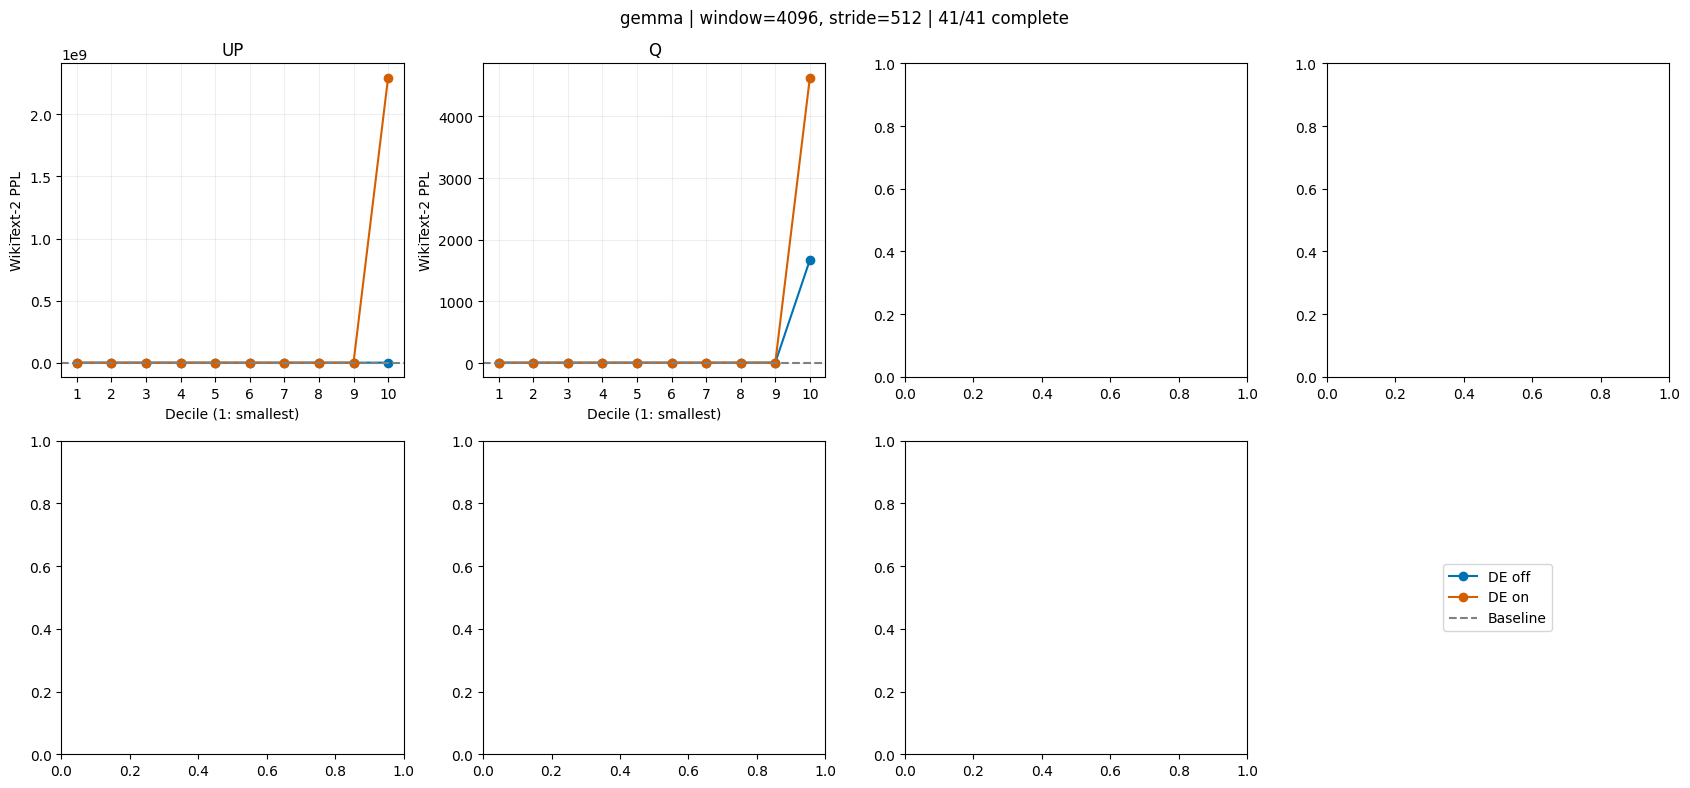

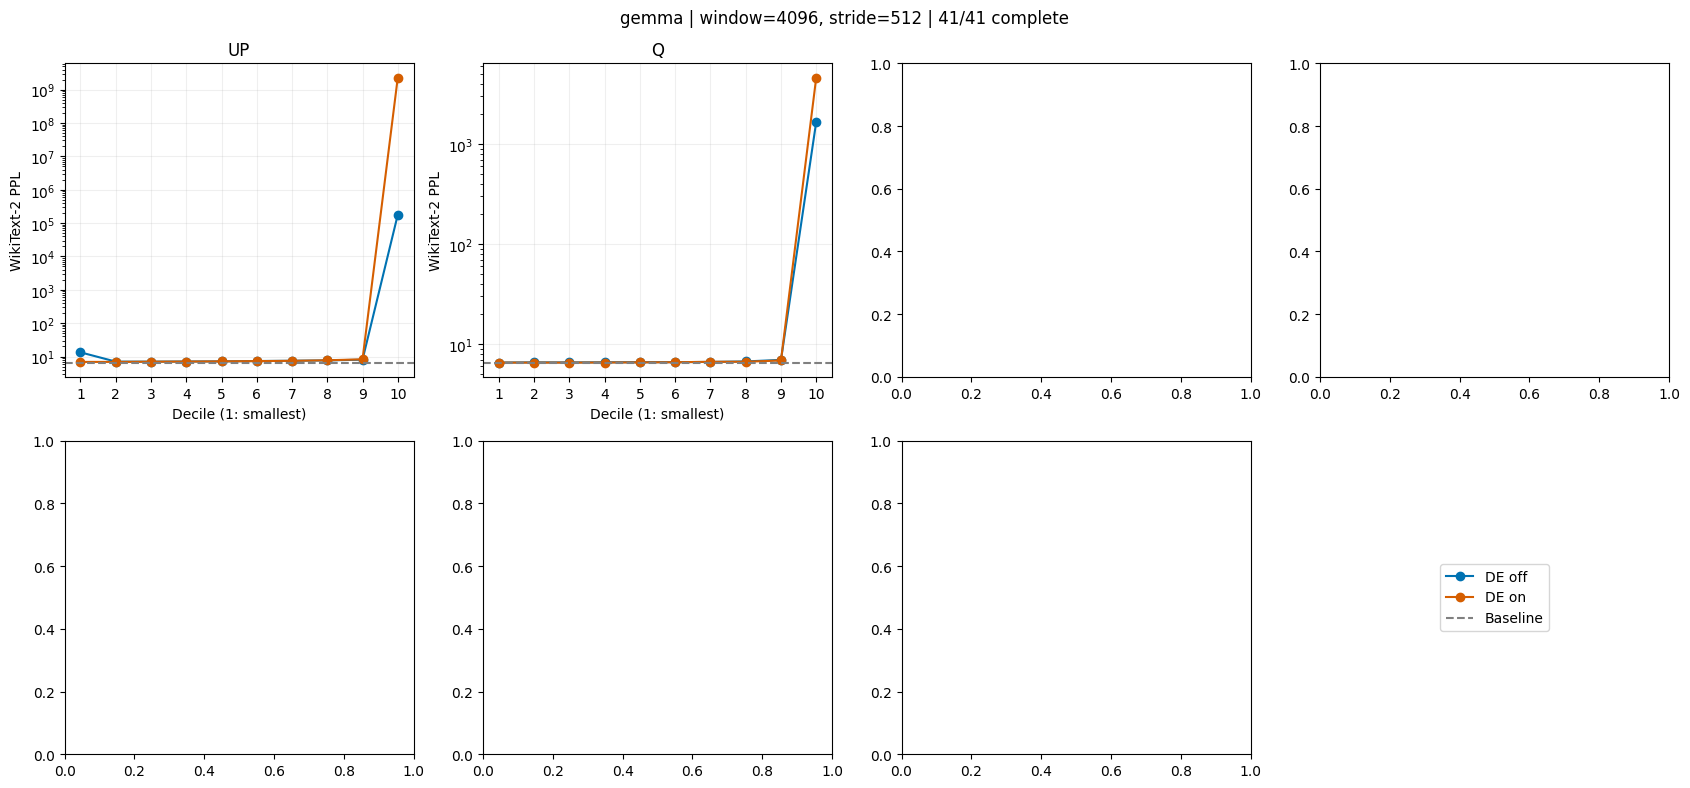

In [6]:
# 実行後、または別セッションで保存済みplanを指定して分析可能（モデル読込不要）。
ANALYSIS_PLAN = globals().get('PLAN_PATH', None)
# ANALYSIS_PLAN = OUTPUT/'plans'/'gemma_....json'
if ANALYSIS_PLAN is None:
    print('保存済みplanをANALYSIS_PLANに指定してください:', list((OUTPUT/'plans').glob('*.json')))
else:
    plan=json.loads(Path(ANALYSIS_PLAN).read_text()); rows=[]; missing=[]
    for spec in plan:
        result=read_result(spec)
        if result is None: missing.append(spec['condition']); continue
        rows.append(dict(**spec['condition'],ppl=result['ppl'],overflow=result['ppl_overflow'],seconds=result['seconds']))
    df=pd.DataFrame(rows)
    print(f'完了 {len(rows)}/{len(plan)}; 未完了 {len(missing)}', missing[:5])
    out=OUTPUT/'analysis'/Path(ANALYSIS_PLAN).stem; out.mkdir(parents=True,exist_ok=True)
    if len(df):
        df.to_csv(out/'ppl.csv',index=False); display(df)
        baseline=df.loc[df.group=='baseline','ppl']
        if len(baseline) and pd.notna(baseline.iloc[0]):
            baseline=float(baseline.iloc[0])
            for scale in ('linear','log'):
                fig,axes=plt.subplots(2,4,figsize=(17,8),squeeze=False)
                for ax,g in zip(axes.flat,GROUPS):
                    for de,color,label in [(False,'#0072B2','DE off'),(True,'#D55E00','DE on')]:
                        d=df[(df.group==g)&(df.de==de)].set_index('decile').reindex(range(1,11))
                        ax.plot(d.index,d.ppl,marker='o',color=color,label=label)
                    ax.axhline(baseline,color='gray',ls='--',label='Baseline')
                    ax.set(title=g,xlabel='Decile (1: smallest)',ylabel='WikiText-2 PPL',yscale=scale,xticks=range(1,11))
                    ax.grid(alpha=.2)
                axes.flat[-1].axis('off')
                handles,labels=axes.flat[0].get_legend_handles_labels()
                axes.flat[-1].legend(handles,labels,loc='center')
                fig.suptitle(f"{plan[0]['model']} | window={plan[0]['window']}, stride={plan[0]['stride']} | {len(rows)}/{len(plan)} complete")
                fig.tight_layout(); fig.savefig(out/f'deciles_{scale}.pdf',bbox_inches='tight')
                fig.savefig(out/f'deciles_{scale}.png',dpi=160,bbox_inches='tight'); plt.show()
        # 欠測は補間せず、未完了・overflowを実測値と区別する。


In [7]:
from google.colab import drive, runtime

drive.flush_and_unmount()
print("Colabランタイムを解放します。")
runtime.unassign()

Colabランタイムを解放します。
